# Optimisation différentiable sans contrainte — série d'exercices

**OURBANI DOUBLA MAMOUDOU IBRAHIMA** — SDIA 4, ENSPD (2026-2027)

Ce notebook résout les exercices du dossier `exercices/` (un fichier par exercice) avec nos propres
implémentations. Chaque algorithme est dans son propre fichier à la racine du dossier :
`gradient_pas_fixe.py`, `gradient_pas_optimal.py`, `gradient_conjugue.py`, `newton.py`, `quasi_newton.py`.
Les outils communs (algèbre linéaire, recherches linéaires, résultat) sont dans `outils/`.
Les algorithmes sont écrits à la main : pas de `scipy.optimize`, pas de `numpy.linalg`. Les systèmes linéaires sont
résolus par Gauss (pivot partiel) ou Cholesky, les valeurs propres par la méthode de Jacobi, et les recherches
linéaires (Armijo, Wolfe, section dorée) sont codées dans `outils/recherche_lineaire.py`.
`numpy` sert seulement à stocker les vecteurs, `sympy` à dériver f exactement (sinon : différences finies),
`matplotlib` seulement aux graphiques.

| Méthode | Direction $d_k$ | Pas $\alpha_k$ |
|---|---|---|
| Gradient à pas fixe | $-\nabla f(x_k)$ | constant ($0<\alpha<2/\lambda_{\max}$) |
| Gradient à pas optimal | $-\nabla f(x_k)$ | $\arg\min_{\alpha>0} f(x_k+\alpha d_k)$ (section dorée) |
| Gradient conjugué (Polak-Ribière+) | $-\nabla f(x_{k}) + \beta_{k} d_{k-1}$ | pas optimal |
| Newton | $\nabla^2 f(x_k)\, d_k = -\nabla f(x_k)$ | 1 près du minimum (Armijo sinon) |
| Quasi-Newton BFGS | $-W_k \nabla f(x_k)$, $W_k \approx \nabla^2 f(x_k)^{-1}$ | Wolfe |

Critère d'arrêt : $\|\nabla f(x_k)\| \le 10^{-6}$ (sauf mention contraire).

In [1]:
import sys
sys.path.insert(0, "..")          # dossier parent : un fichier par algorithme + outils/

import numpy as np
import matplotlib.pyplot as plt

from gradient_pas_fixe import gradient_pas_fixe
from gradient_pas_optimal import gradient_pas_optimal
from gradient_conjugue import gradient_conjugue
from newton import newton
from quasi_newton import quasi_newton
from minimiser import minimiser, comparer
from outils.graphiques import tracer_trajectoires, tracer_convergence
from exercices import EXERCICES, exercice

%matplotlib inline

## Exercice 0 — exercice du cours

$f(x,y,z) = 6x^2 + 6xy + 3y^2 + y^3 - \frac{z^3}{3} + \frac{z^4}{4}$, $X_0 = (-0.6637;\ 0.1758;\ 1.5778)$, tolérance $10^{-5}$.

$\nabla f = (12x+6y,\ 6x+6y+3y^2,\ z^3-z^2)$. La 3e composante donne $z\in\{0,1\}$, la 1re $y=-2x$, puis la 2e
$6x(2x-1)=0$. Points critiques : $(0,0,0)$, $(0,0,1)$, $(\tfrac12,-1,0)$, $(\tfrac12,-1,1)$.

$\nabla^2 f(0,0,1) = \begin{pmatrix}12&6&0\\6&6&0\\0&0&1\end{pmatrix}$ est définie positive (mineurs 12, 36, 36) :
minimum local, $f = -\frac13+\frac14 = -\frac1{12}$.

In [2]:
# chaque algorithme s'appelle directement depuis son fichier
f = "6*x**2 + 6*x*y + 3*y**2 + y**3 - z**3/3 + z**4/4"
x0 = [-0.6637, 0.1758, 1.5778]

r = newton(f, x0, tol=1e-5)
r.afficher_iterations()
print()
print(r)

    k             f(x_k)   ||grad f||         pas   x_k
    0        2.281123142    7.606e+00           -   (-0.6637, 0.1758, 1.5778)
    1     -0.04209391345    3.846e-01           1   (-0.011433, 0.022866, 1.24428)
    2     -0.08073792829    7.870e-02           1   (-0.000249994, 0.000499987, 1.06887)
    3     -0.08330210225    7.986e-03           1   (-1.24869e-07, 2.49737e-07, 1.00786)
    4     -0.08333332604    1.208e-04           1   (-3.11843e-14, 6.23687e-14, 1.00012)
    5     -0.08333333333    2.916e-08           1   (-1.93744e-27, 3.87488e-27, 1)

Methode            : Newton
Converge           : oui
Iterations         : 5
x*                 : (-1.9374424e-27, 3.8748848e-27, 1)
f(x*)              : -0.08333333333
||grad f(x*)||     : 2.916e-08
Evaluations f/g/H  : 6 / 6 / 5
Message            : convergence
Nature du point    : minimum local strict (hessienne definie positive)


In [3]:
# les 5 methodes sur l'exercice 0 (exercices/exercice_0_cours.py)
e = exercice(0)
res = e.comparer()

methode                                  iter            f(x*)   ||grad||       eval f/g/H   ok   x*
gradient a pas fixe (alpha=0.05)          197   -0.08333333328   9.91e-06        198/198/0  oui   (-7.26705e-12, 1.17583e-11, 1.00001)
gradient a pas optimal                     31   -0.08333333329   9.24e-06        1623/32/0  oui   (1.39538e-07, 8.62388e-08, 1.00001)
gradient conjugue (PR, pas exact)           9   -0.08333333333   1.32e-07         472/10/0  oui   (-1.00712e-08, 3.88068e-10, 1)
Newton                                      5   -0.08333333333   2.92e-08            6/6/5  oui   (-1.93744e-27, 3.87488e-27, 1)
quasi-Newton BFGS                          13   -0.08333333333   1.64e-07          15/15/0  oui   (-2.73315e-08, 4.99103e-08, 1)


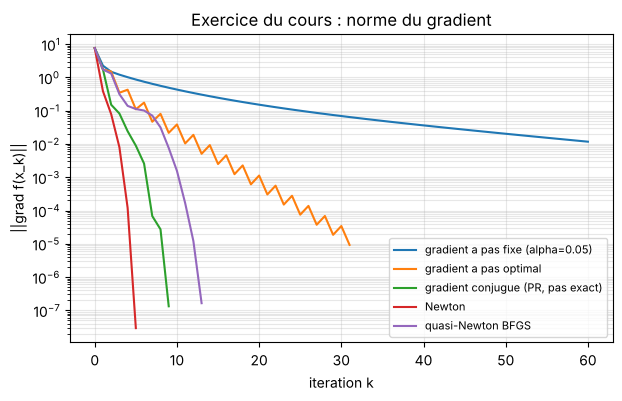

In [4]:
tracer_convergence(res, titre="Exercice du cours : norme du gradient", max_iter=60)
plt.show()

On retrouve les vitesses de convergence du cours : linéaire pour les deux méthodes de gradient, superlinéaire
pour BFGS, quadratique pour Newton (le nombre de chiffres exacts double à chaque itération à la fin).

## Exercice 1 — quadratique en dimension 2

$f(x,y) = 2x^2 + xy + y^2 - 3x + 2y = \frac12 X^\top A X - b^\top X$ avec
$A = \begin{pmatrix}4&1\\1&2\end{pmatrix}$, $b = \begin{pmatrix}3\\-2\end{pmatrix}$.

Mineurs principaux : $4>0$ et $\det A = 7>0$, donc $A$ est définie positive et f strictement convexe.
Le minimum vérifie $AX=b$ :
$X^* = \frac17\begin{pmatrix}2&-1\\-1&4\end{pmatrix}\begin{pmatrix}3\\-2\end{pmatrix} = \left(\frac87,\ -\frac{11}7\right)$,
$f(X^*) = -\frac12 b^\top X^* = -\frac{23}{7}$.

Valeurs propres de A : $3\pm\sqrt2$, donc le pas fixe doit vérifier $\alpha < 2/(3+\sqrt2) \approx 0.453$.

In [5]:
e = exercice(1)
res = e.comparer()
print("solution exacte :", 8/7, -11/7, "  f* =", -23/7)

methode                                  iter            f(x*)   ||grad||       eval f/g/H   ok   x*
gradient a pas fixe (alpha=0.2)            40     -3.285714286   7.60e-07          41/41/0  oui   (1.14286, -1.57143)
gradient a pas optimal                     19     -3.285714286   6.14e-07        1004/20/0  oui   (1.14286, -1.57143)
gradient conjugue (PR, pas exact)           2     -3.285714286   6.35e-08          105/3/0  oui   (1.14286, -1.57143)
Newton                                      1     -3.285714286   6.28e-16            2/2/1  oui   (1.14286, -1.57143)
quasi-Newton BFGS                           8     -3.285714286   4.33e-08            9/9/0  oui   (1.14286, -1.57143)
solution exacte : 1.1428571428571428 -1.5714285714285714   f* = -3.2857142857142856


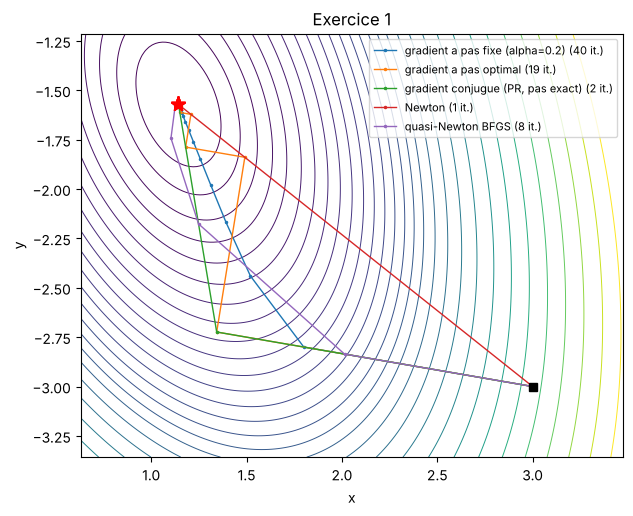

In [6]:
tracer_trajectoires(e.probleme(), res, titre="Exercice 1")
plt.show()

In [7]:
# pas fixe : on depasse 2/lambda_max = 0.453
for a in (0.1, 0.2, 0.4, 0.45, 0.46):
    r = e.resoudre("pas_fixe", alpha=a, max_iter=5000)
    print(f"alpha = {a:<5} iterations = {r.iterations:<5} converge = {r.converge}")

alpha = 0.1   iterations = 87    converge = True
alpha = 0.2   iterations = 40    converge = True
alpha = 0.4   iterations = 58    converge = True
alpha = 0.45  iterations = 1129  converge = True
alpha = 0.46  iterations = 555   converge = False


Newton converge en 1 itération (f est quadratique, la direction de Newton pointe exactement sur le minimum)
et le gradient conjugué en 2 itérations (= dimension). Pour le pas fixe, au-delà de 0.453 la suite diverge
comme prévu.

## Exercice 2 — fonction de Rosenbrock

$f(x,y) = (1-x)^2 + 100(y-x^2)^2$, départ $(-1.2,\ 1)$.

$\nabla f = \left(-2(1-x) - 400x(y-x^2),\ 200(y-x^2)\right)$. La 2e composante impose $y=x^2$, puis la 1re $x=1$ :
seul point critique $(1,1)$, et $f\ge 0 = f(1,1)$, c'est le minimum global.

$\nabla^2 f(1,1) = \begin{pmatrix}802&-400\\-400&200\end{pmatrix}$, valeurs propres $\approx 0.4$ et $1001.6$ :
conditionnement $\approx 2500$. Les méthodes de gradient, dont la vitesse dépend du conditionnement, vont être très lentes
au fond de la vallée.

In [8]:
e = exercice(2)
res = e.comparer()

methode                                  iter            f(x*)   ||grad||       eval f/g/H   ok   x*
gradient a pas fixe (alpha=0.001)       32076  1.251723677e-12   1.00e-06    32077/32077/0  oui   (0.999999, 0.999998)
gradient a pas optimal                  14722  7.018151605e-13   1.00e-06   736153/14723/0  oui   (0.999999, 0.999998)
gradient conjugue (PR, pas exact)          23  5.597064158e-20   2.11e-10        1170/24/0  oui   (1, 1)
Newton                                     21  3.742059567e-21   4.47e-10         29/22/21  oui   (1, 1)
quasi-Newton BFGS                          39  5.584260385e-20   8.97e-09          50/50/0  oui   (1, 1)


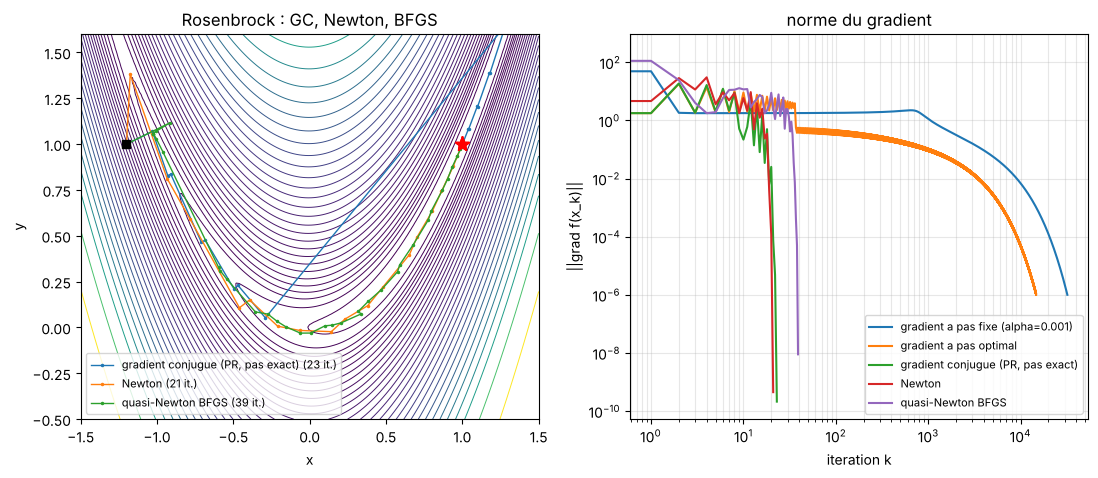

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
tracer_trajectoires(e.probleme(), res[2:], cadre=(-1.5, 1.5, -0.5, 1.6), ax=ax[0], titre="Rosenbrock : GC, Newton, BFGS")
tracer_convergence(res, ax=ax[1], titre="norme du gradient")
ax[1].set_xscale("log")
plt.show()

Le pas fixe demande plus de 30 000 itérations et le pas optimal plus de 14 000 : la direction $-\nabla f$ est presque
perpendiculaire à la vallée, on avance en zigzag. Newton et BFGS suivent la courbure de la vallée et convergent
en quelques dizaines d'itérations.

## Exercice 3 — fonction de Himmelblau

$f(x,y) = (x^2+y-11)^2 + (x+y^2-7)^2 \ge 0$ et $f(3,2) = 0^2 + 0^2 = 0$ : $(3,2)$ est un minimum global.
f possède en tout quatre minima globaux (f = 0), un maximum local et quatre points selles.
Le minimum obtenu dépend donc du point de départ (et même de la méthode).

In [10]:
e = exercice(3)
for x0 in ([0, 0], [-1, 1], [-4, -4], [4, -2]):
    print(f"x0 = {x0}")
    res = e.comparer(x0=x0)
    print()

x0 = [0, 0]
methode                                  iter            f(x*)   ||grad||       eval f/g/H   ok   x*
gradient a pas fixe (alpha=0.01)           62   1.44754892e-14   8.63e-07          63/63/0  oui   (3, 2)
gradient a pas optimal                     23  2.684637059e-15   4.22e-07        1189/24/0  oui   (3, 2)
gradient conjugue (PR, pas exact)          10  4.422506327e-23   8.49e-11         516/11/0  oui   (3, 2)
Newton                                      7  1.128355337e-16   8.38e-08           24/8/7  oui   (3.58443, -1.84813)
quasi-Newton BFGS                          10  6.278310655e-15   8.16e-07          17/17/0  oui   (3, 2)

x0 = [-1, 1]
methode                                  iter            f(x*)   ||grad||       eval f/g/H   ok   x*
gradient a pas fixe (alpha=0.01)           22  5.896757524e-15   8.74e-07          23/23/0  oui   (-2.80512, 3.13131)
gradient a pas optimal                      9   4.81751037e-15   8.11e-07         448/10/0  oui   (-2.80512, 3.13131

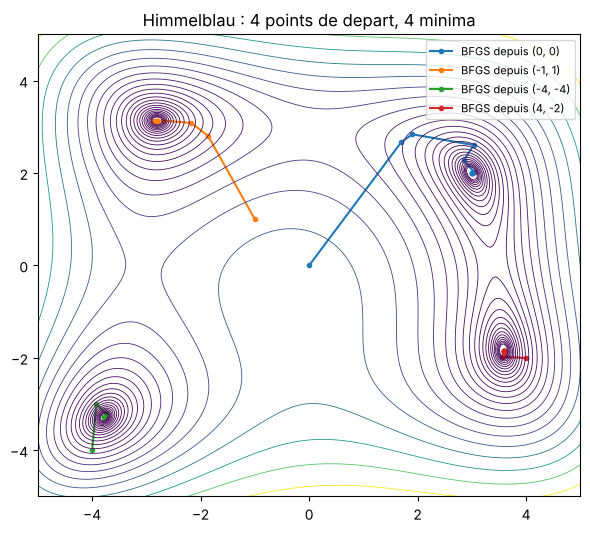

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))
for x0 in ([0, 0], [-1, 1], [-4, -4], [4, -2]):
    r = e.resoudre("bfgs", x0=x0)
    c = np.array([h[1] for h in r.historique])
    ax.plot(c[:, 0], c[:, 1], "o-", ms=3, label=f"BFGS depuis {tuple(x0)}")
xs = np.linspace(-5, 5, 200)
X, Y = np.meshgrid(xs, xs)
Z = (X**2 + Y - 11)**2 + (X + Y**2 - 7)**2
ax.contour(X, Y, Z, levels=np.logspace(-0.5, 2.7, 25), cmap="viridis", linewidths=0.6)
ax.legend(fontsize=8); ax.set_title("Himmelblau : 4 points de depart, 4 minima")
plt.show()

Depuis $(0,0)$, toutes les méthodes vont en $(3,2)$ sauf Newton qui atteint $(3.584, -1.848)$ :
la hessienne n'est pas définie positive en $(0,0)$ (on est près du maximum local), la direction de Newton
modifiée part ailleurs. Un minimum local n'est pas unique : il faut toujours préciser le point de départ.

## Exercice 4 — régression linéaire par moindres carrés

$S(a,b) = \sum_i (a t_i + b - y_i)^2$. Équations normales ($\nabla S = 0$) :
$$a\sum t_i^2 + b\sum t_i = \sum t_i y_i, \qquad a\sum t_i + n b = \sum y_i$$
avec $\sum t_i = 21$, $\sum t_i^2 = 91$, $\sum y_i = 48.3$, $\sum t_i y_i = 204.4$, $n=6$ :
$91a + 21b = 204.4$ et $21a + 6b = 48.3$, d'où $a = 2.02$ et $b = 0.98$.

La hessienne $2\begin{pmatrix}91&21\\21&6\end{pmatrix}$ est constante et définie positive :
$S$ est quadratique convexe, Newton converge en 1 itération.

In [12]:
e = exercice(4)
res = e.comparer()
a, b = res[3].x
print(f"\ndroite : y = {a:.4f} t + {b:.4f}")
print(f"prevision pour t = 8 : {a*8 + b:.2f} millions FCFA")

methode                                  iter            f(x*)   ||grad||       eval f/g/H   ok   x*
gradient a pas fixe (alpha=0.005)        1263            0.128   9.92e-07      1264/1264/0  oui   (2.02, 0.98)
gradient a pas optimal                      5            0.128   4.36e-07          251/6/0  oui   (2.02, 0.98)
gradient conjugue (PR, pas exact)           2            0.128   3.15e-07           97/3/0  oui   (2.02, 0.98)
Newton                                      1            0.128   5.68e-14            2/2/1  oui   (2.02, 0.98)
quasi-Newton BFGS                           6            0.128   5.68e-14          11/11/0  oui   (2.02, 0.98)

droite : y = 2.0200 t + 0.9800
prevision pour t = 8 : 17.14 millions FCFA


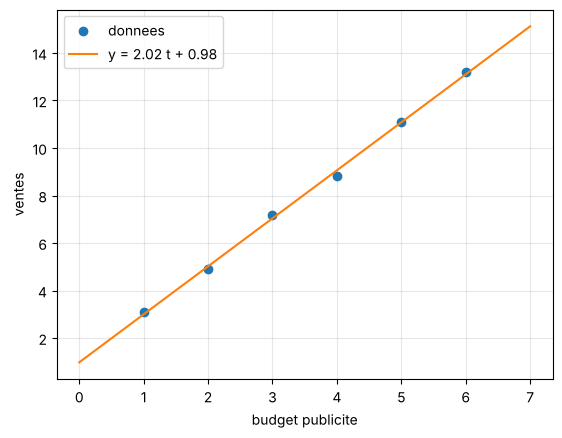

In [13]:
from exercices.exercice_4_regression_lineaire import T_PUB, VENTES
t = np.linspace(0, 7, 50)
plt.plot(T_PUB, VENTES, "o", label="donnees")
plt.plot(t, a*t + b, label=f"y = {a:.2f} t + {b:.2f}")
plt.xlabel("budget publicite"); plt.ylabel("ventes"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

## Exercice 5 — fonction non quadratique de trois variables

$f(x,y,z) = (x-1)^2 + (y-2)^2 + (z-3)^2 + (xyz-6)^2$ est une somme de carrés, donc $f\ge0$, et
$f(1,2,3) = 0$ car $1\cdot2\cdot3 = 6$ : c'est le minimum global (et le seul point où f s'annule).

$\nabla f = \begin{pmatrix}2(x-1) + 2(xyz-6)\,yz\\ 2(y-2) + 2(xyz-6)\,xz\\ 2(z-3) + 2(xyz-6)\,xy\end{pmatrix}$.

Remarque : en $(0,0,0)$, $\nabla f = (-2,-4,-6)$, donc $-\nabla f$ est dirigé vers $(1,2,3)$ et le pas optimal
y arrive en une seule itération. C'est pour cela qu'on part de $(2,1,1)$.

In [14]:
e = exercice(5)
res = e.comparer()
print()
print("depuis (0, 0, 0) :", e.resoudre("pas_optimal", x0=[0, 0, 0]))

methode                                  iter            f(x*)   ||grad||       eval f/g/H   ok   x*
gradient a pas fixe (alpha=0.01)          755   2.46784005e-13   9.94e-07        756/756/0  oui   (1, 2, 3)
gradient a pas optimal                    366  1.162592683e-13   9.26e-07      18995/367/0  oui   (1, 2, 3)
gradient conjugue (PR, pas exact)          11  2.244379705e-17   1.91e-08         568/12/0  oui   (1, 2, 3)
Newton                                      8  4.902422561e-16   1.46e-07           14/9/8  oui   (1, 2, 3)
quasi-Newton BFGS                          19  1.456864177e-17   4.94e-08          20/20/0  oui   (1, 2, 3)

depuis (0, 0, 0) : Methode            : gradient a pas optimal
Converge           : oui
Iterations         : 1
x*                 : (1, 2, 3)
f(x*)              : 7.064230417e-19
||grad f(x*)||     : 1.176e-08
Evaluations f/g/H  : 54 / 2 / 0
Message            : convergence
Nature du point    : minimum local strict (hessienne definie positive)


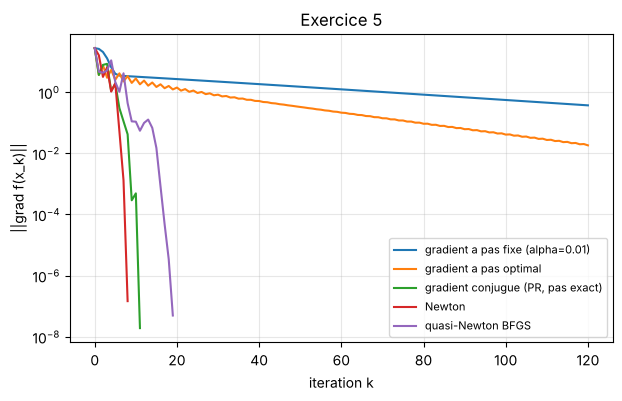

In [15]:
tracer_convergence(res, titre="Exercice 5", max_iter=120)
plt.show()

## Exercice 6 — maximisation d'un profit

$P(x,y) = 50x + 60y - x^2 - xy - y^2$. Conditions d'optimalité :
$\partial_x P = 50 - 2x - y = 0$ et $\partial_y P = 60 - x - 2y = 0$, d'où $x = \frac{40}{3}$, $y = \frac{70}{3}$.

$\nabla^2 P = \begin{pmatrix}-2&-1\\-1&-2\end{pmatrix}$ est définie négative : c'est bien un maximum de P
(un minimum de $f=-P$). Profit maximal : $P^* = \frac{3100}{3} \approx 1033.33$ milliers FCFA.

In [16]:
e = exercice(6)
res = e.comparer()
x, y = res[3].x
print(f"\nproduction optimale : x = {x:.4f}, y = {y:.4f} (centaines d'unites)")
print(f"profit maximal      : {-res[3].f:.2f} milliers FCFA")

methode                                  iter            f(x*)   ||grad||       eval f/g/H   ok   x*
gradient a pas fixe (alpha=0.3)            45     -1033.333333   7.57e-07          46/46/0  oui   (13.3333, 23.3333)
gradient a pas optimal                      9     -1033.333333   4.08e-07         478/10/0  oui   (13.3333, 23.3333)
gradient conjugue (PR, pas exact)           2     -1033.333333   6.93e-07          109/3/0  oui   (13.3333, 23.3333)
Newton                                      1     -1033.333333   1.59e-14            2/2/1  oui   (13.3333, 23.3333)
quasi-Newton BFGS                           6     -1033.333333   4.11e-10            9/9/0  oui   (13.3333, 23.3333)

production optimale : x = 13.3333, y = 23.3333 (centaines d'unites)
profit maximal      : 1033.33 milliers FCFA


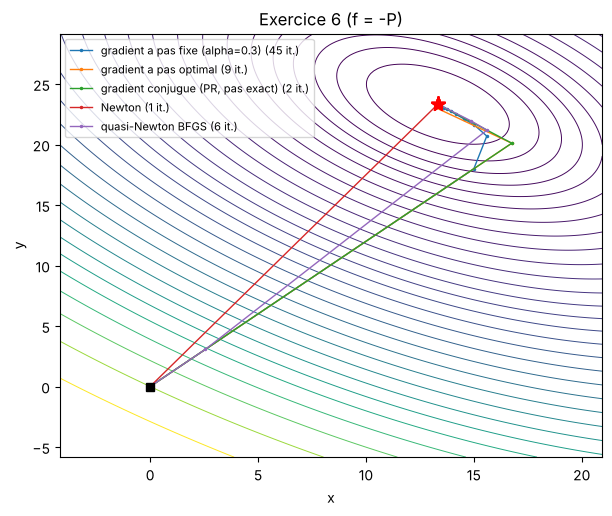

In [17]:
tracer_trajectoires(e.probleme(), res, titre="Exercice 6 (f = -P)")
plt.show()

## Exercice 7 — quadratique en dimension 10

$f(x) = \frac12 x^\top A x - b^\top x$ avec $A = \mathrm{tridiag}(-1, 2, -1)$, $b = (1,\dots,1)$.

$x^\top A x = x_1^2 + \sum_{i=1}^{9}(x_i - x_{i+1})^2 + x_{10}^2 > 0$ pour $x \ne 0$ : A est définie positive.
On vérifie que $x_i = i(11-i)/2$ résout $Ax = b$ : $-x_{i-1} + 2x_i - x_{i+1} = 1$.

Valeurs propres : $\lambda_k = 2 - 2\cos\frac{k\pi}{11}$, donc $\kappa = \lambda_{10}/\lambda_1 \approx 48$.
Le gradient conjugué avec pas exact termine en au plus $n = 10$ itérations.

In [18]:
e = exercice(7)
print(e.probleme())
res = e.comparer()
print("\nsolution GC :", np.round(res[2].x, 6))
print("attendue    :", e.solution)

f(x1, x2, x3, x4, x5, x6, x7, x8, x9, x10) = x1**2 - x1*x2 - x1 + x10**2 - x10*x9 - x10 + x2**2 - x2*x3 - x2 + x3**2 - x3*x4 - x3 + x4**2 - x4*x5 - x4 + x5**2 - x5*x6 - x5 + x6**2 - x6*x7 - x6 + x7**2 - x7*x8 - x7 + x8**2 - x8*x9 - x8 + x9**2 - x9
methode                                  iter            f(x*)   ||grad||       eval f/g/H   ok   x*
gradient a pas fixe (alpha=0.25)          729              -55   9.86e-07        730/730/0  oui   (5, 9, 12, 14, 15, 15, 14, 12, 9, 5)
gradient a pas optimal                    326              -55   8.77e-07      17260/327/0  oui   (5, 9, 12, 14, 15, 15, 14, 12, 9, 5)
gradient conjugue (PR, pas exact)           5              -55   9.27e-07          270/6/0  oui   (5, 9, 12, 14, 15, 15, 14, 12, 9, 5)
Newton                                      1              -55   7.11e-15            2/2/1  oui   (5, 9, 12, 14, 15, 15, 14, 12, 9, 5)
quasi-Newton BFGS                          10              -55   6.60e-07          13/13/0  oui   (5, 9, 12, 14

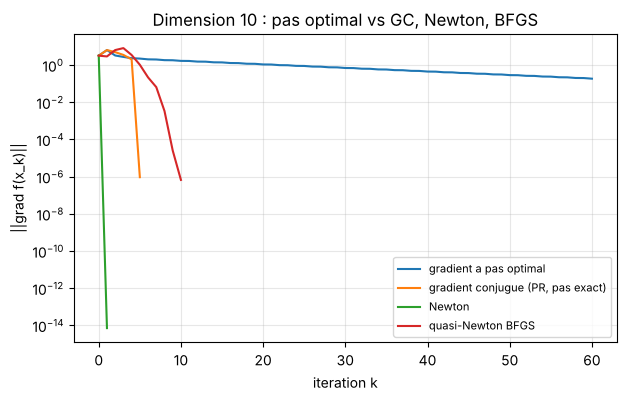

In [19]:
tracer_convergence(res[1:], titre="Dimension 10 : pas optimal vs GC, Newton, BFGS", max_iter=60)
plt.show()

Le gradient conjugué s'arrête en 5 itérations (moins que 10) : b est symétrique et n'excite que 5 des
10 directions propres de A, l'espace de Krylov est de dimension 5. Le pas optimal, lui, en demande plus de 300
à cause du conditionnement (≈ 48). C'est l'exercice où l'intérêt du gradient conjugué est le plus net.

## Résoudre un autre exercice avec nos fonctions

Il suffit d'écrire f sous forme de chaîne (les variables sont détectées puis rangées : x, y, z ou x1, x2, ..., x10)
ou de donner une fonction Python. Exemple :

In [20]:
r = minimiser("x**2 + 2*y**2 + exp(x - y)", x0=[1, 1], methode="newton")
print(r)
print()
comparer("x**2 + 2*y**2 + exp(x - y)", [1, 1]);

Methode            : Newton
Converge           : oui
Iterations         : 3
x*                 : (-0.3127668, 0.1563834)
f(x*)              : 0.7722682277
||grad f(x*)||     : 3.144e-08
Evaluations f/g/H  : 4 / 4 / 3
Message            : convergence
Nature du point    : minimum local strict (hessienne definie positive)

methode                                  iter            f(x*)   ||grad||       eval f/g/H   ok   x*
gradient a pas fixe (alpha=0.184699)       26     0.7722682277   5.59e-07          27/27/0  oui   (-0.312767, 0.156383)
gradient a pas optimal                     12     0.7722682277   9.08e-07         628/13/0  oui   (-0.312767, 0.156384)
gradient conjugue (PR, pas exact)           2     0.7722682277   2.85e-08          103/3/0  oui   (-0.312767, 0.156383)
Newton                                      3     0.7722682277   3.14e-08            4/4/3  oui   (-0.312767, 0.156383)
quasi-Newton BFGS                           6     0.7722682277   3.34e-07            7/7/0  oui  

In [21]:
# avec une fonction python (gradient exact facultatif, sinon differences finies)
def f(X):
    a, b = X
    return (a - 3)**2 + (a*b - 1)**2

print(minimiser(f, [0.5, 0.5], methode="bfgs"))

Methode            : quasi-Newton BFGS
Converge           : oui
Iterations         : 9
x*                 : (3, 0.33333334)
f(x*)              : 3.661413466e-17
||grad f(x*)||     : 3.479e-08
Evaluations f/g/H  : 55 / 11 / 0
Message            : convergence
Nature du point    : minimum local strict (hessienne definie positive)


En ligne de commande (depuis le dossier principal, sans ouvrir le notebook) :

```bash
python newton.py                                   # Newton sur l'exercice du cours
python newton.py "x**2 + 3*y**2 - x*y" 1 1         # Newton sur une autre fonction
python exercices/exercice_3_xxx.py                 # un exercice, toutes les méthodes
python exercices/exercice_3_xxx.py newton          # un exercice, une méthode
python resoudre.py -f "x**2 + 3*y**2 - x*y" --x0 1 1
python verifier.py                                 # tous les exercices, toutes les méthodes
```

## Bilan

Nombre d'itérations de chaque méthode sur chaque exercice :

In [22]:
import verifier
verifier.main()

Nombre d'iterations   * = resultat faux ou non converge
                      ~ = echec attendu (limite de la methode, voir l'enonce)

exercice                                        pas fixe    pas opt. grad. conj.      Newton        BFGS
 0 Exercice du cours                                197          31           9           5          13 
 1 Quadratique en dimension 2                        40          19           2           1           8 


 2 Fonction de Rosenbrock                         32076       14722          23          21          39 
 3 Fonction de Himmelblau (plusieurs minima)         62          23          10           7          10 
 4 Regression lineaire par moindres carres         1263           5           2           1           6 


 5 Fonction non quadratique de trois variabl        755         366          11           8          19 
 6 Maximisation d'un profit                          45           9           2           1           6 


 7 Quadratique en dimension 10                      729         326           5           1          10 

0 echec(s) - 4.2 s
